# Biomarker Discovery with Machine Learning
## Part 2 of 3: Cross-validated Model Comparison

**Question.** How well can urinary metabolite profiles predict cachexia, and is a sparse (Lasso) panel competitive with dense models?

**Validation design** (small n = 77, so variance matters):
- **Repeated stratified 5-fold CV** (10 repeats = 50 test folds) gives mean ± std
- All preprocessing (log₂, scaling, optional PQN) lives **inside** a scikit-learn `Pipeline`, so nothing is fitted on test folds
- The Lasso regularisation strength is tuned by an **inner** CV (nested), so there is no optimistic tuning on test data
- Metrics: ROC-AUC, balanced accuracy, sensitivity and specificity, with the positive class explicitly set to **Cachexic**
- Baselines: majority-class predictor **and** a one-feature model using only the urine dilution factor (Notebook 1 showed it is strongly group-dependent)


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("../../data/human_cachexia.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
PALETTE = {"Cachexic": "#E74C3C", "Control": "#3498DB"}

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

df = pd.read_csv(DATA)
X = df.drop(columns=["Sample", "Condition"])
y = (df["Condition"] == "Cachexic").astype(int)   # 1 = Cachexic (positive class)
print(f"{X.shape[0]} patients x {X.shape[1]} metabolites; cachexic = {y.sum()}, control = {(1 - y).sum()}")


77 patients x 63 metabolites; cachexic = 47, control = 30


## 1. Models and pipelines

In [2]:
class PQN(BaseEstimator, TransformerMixin):
    """Probabilistic quotient normalisation; reference fitted on training folds only."""
    def fit(self, X, y=None):
        self.reference_ = np.median(np.asarray(X, float), axis=0)
        return self
    def transform(self, X):
        X = np.asarray(X, float)
        return X / np.median(X / self.reference_, axis=1, keepdims=True)

class DilutionFactor(BaseEstimator, TransformerMixin):
    """Single feature: log2 PQN dilution factor (overall urine concentration)."""
    def fit(self, X, y=None):
        self.reference_ = np.median(np.asarray(X, float), axis=0)
        return self
    def transform(self, X):
        X = np.asarray(X, float)
        return np.log2(np.median(X / self.reference_, axis=1, keepdims=True))

def make_pipeline(clf, pqn=False):
    steps = [("pqn", PQN())] if pqn else []
    steps += [("log2", FunctionTransformer(np.log2)), ("scale", StandardScaler()), ("clf", clf)]
    return Pipeline(steps)

MODELS = {
    "Lasso logistic (L1, nested C)": LogisticRegressionCV(
        Cs=np.logspace(-2, 1, 12), penalty="l1", solver="liblinear", cv=5,
        scoring="roc_auc", class_weight="balanced", random_state=42),
    "Ridge logistic (L2)": LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000),
    "Random Forest": RandomForestClassifier(n_estimators=500, class_weight="balanced",
                                            random_state=42, n_jobs=-1),
    "Majority class": DummyClassifier(strategy="most_frequent"),
}
SCORING = {
    "ROC-AUC": "roc_auc",
    "Balanced Acc": "balanced_accuracy",
    "Sensitivity": make_scorer(recall_score, pos_label=1),
    "Specificity": make_scorer(recall_score, pos_label=0),
}
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)


## 2. Repeated cross-validation

In [3]:
rows, fold_auc = [], {}
for pqn in (False, True):
    for name, clf in MODELS.items():
        s = cross_validate(make_pipeline(clf, pqn), X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        label = f"{name}{' + PQN' if pqn else ''}"
        fold_auc[label] = s["test_ROC-AUC"]
        rows.append({"Model": label, **{m: f"{s['test_' + m].mean():.2f} ± {s['test_' + m].std():.2f}" for m in SCORING}})
dil = Pipeline([("dilution", DilutionFactor()), ("clf", LogisticRegression(class_weight="balanced"))])
s = cross_validate(dil, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
fold_auc["Dilution factor only (1 feature)"] = s["test_ROC-AUC"]
rows.append({"Model": "Dilution factor only (1 feature)", **{m: f"{s['test_' + m].mean():.2f} ± {s['test_' + m].std():.2f}" for m in SCORING}})
results = pd.DataFrame(rows).set_index("Model")
results.to_csv("model_comparison.csv")
results


,ROC-AUC,Balanced Acc,Sensitivity,Specificity
Model,,,,
"Lasso logistic (L1, nested C)",0.71 ± 0.12,0.68 ± 0.10,0.70 ± 0.11,0.66 ± 0.19
Ridge logistic (L2),0.78 ± 0.10,0.75 ± 0.10,0.80 ± 0.10,0.70 ± 0.16
Random Forest,0.78 ± 0.10,0.70 ± 0.10,0.75 ± 0.13,0.66 ± 0.17
Majority class,0.50 ± 0.00,0.50 ± 0.00,1.00 ± 0.00,0.00 ± 0.00
"Lasso logistic (L1, nested C) + PQN",0.67 ± 0.12,0.64 ± 0.12,0.67 ± 0.14,0.61 ± 0.20
Ridge logistic (L2) + PQN,0.74 ± 0.10,0.67 ± 0.11,0.76 ± 0.11,0.58 ± 0.18
Random Forest + PQN,0.73 ± 0.12,0.69 ± 0.09,0.85 ± 0.10,0.52 ± 0.17
Majority class + PQN,0.50 ± 0.00,0.50 ± 0.00,1.00 ± 0.00,0.00 ± 0.00
Dilution factor only (1 feature),0.75 ± 0.11,0.69 ± 0.10,0.72 ± 0.11,0.67 ± 0.16


**Reading the table.**
- A single number, the **urine dilution factor**, already reaches ROC-AUC ≈ 0.75. The full 63-metabolite ridge model adds only a few points on top of it (≈ 0.78).
- PQN lowers every model (compare the "+ PQN" rows): once overall concentration is removed, the remaining metabolite-specific pattern supports ROC-AUC ≈ 0.74 at best.
- So roughly speaking, *most of the predictive signal is overall urine concentration*, and a smaller, real part is the relative metabolite pattern.

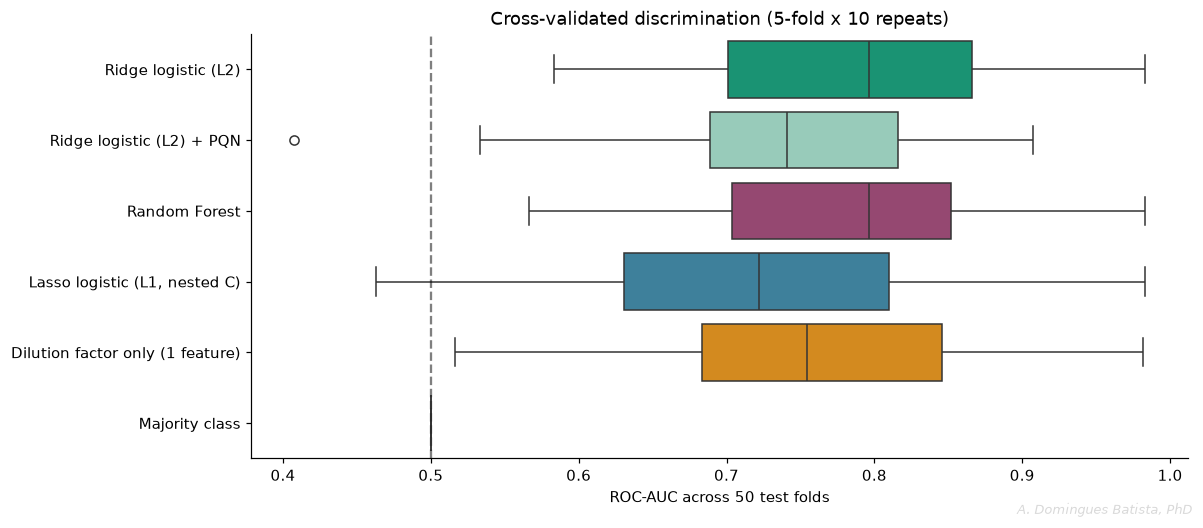

In [4]:
main = ["Ridge logistic (L2)", "Ridge logistic (L2) + PQN", "Random Forest", "Lasso logistic (L1, nested C)",
        "Dilution factor only (1 feature)", "Majority class"]
fig, ax = plt.subplots(figsize=(11, 4.8))
sns.boxplot(data=pd.DataFrame({k: fold_auc[k] for k in main}), orient="h", ax=ax,
            palette=["#06A77D", "#8fd3bd", "#A23B72", "#2E86AB", "#F18F01", "#BBBBBB"])
ax.axvline(0.5, ls="--", c="k", alpha=0.5)
ax.set(xlabel="ROC-AUC across 50 test folds", title="Cross-validated discrimination (5-fold x 10 repeats)")
fig.text(0.99, 0.01, 'A. Domingues Batista, PhD', ha='right', va='bottom', fontsize=8.5, color='gray', alpha=0.3, style='italic')
plt.tight_layout(); plt.savefig(FIG_DIR / "cv_auc.png", bbox_inches="tight"); plt.show()


## 3. Pooled ROC curves and Lasso feature-selection stability

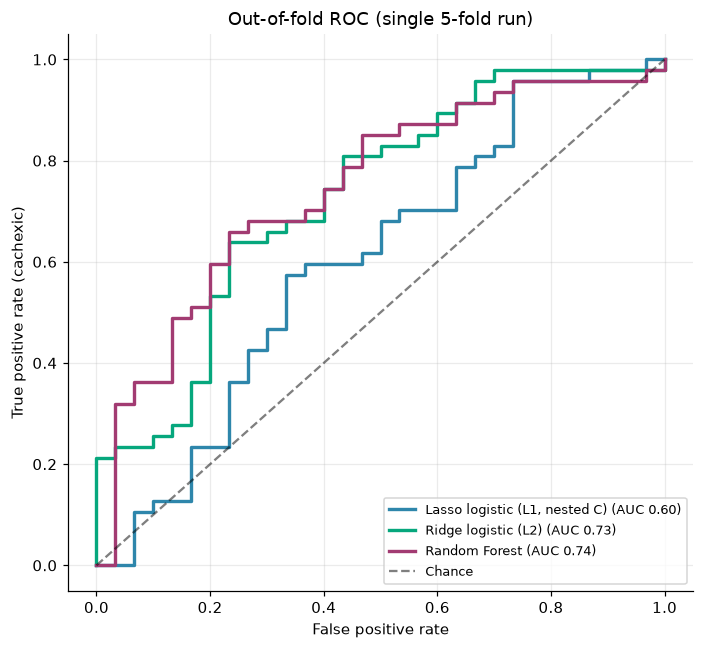

In [5]:
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict

cv1 = StratifiedKFold(5, shuffle=True, random_state=42)
fig, ax = plt.subplots(figsize=(6.5, 6))
for (name, clf), color in zip(list(MODELS.items())[:3], ["#2E86AB", "#06A77D", "#A23B72"]):
    proba = cross_val_predict(make_pipeline(clf), X, y, cv=cv1, method="predict_proba")[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    ax.plot(fpr, tpr, lw=2.2, color=color, label=f"{name} (AUC {roc_auc_score(y, proba):.2f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.5, label="Chance")
ax.set(xlabel="False positive rate", ylabel="True positive rate (cachexic)", title="Out-of-fold ROC (single 5-fold run)")
ax.legend(fontsize=8.5, loc="lower right"); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()


In [6]:
# How often does the nested-CV Lasso select each metabolite across the 50 training folds?
lasso = make_pipeline(MODELS["Lasso logistic (L1, nested C)"])
selected = np.zeros(X.shape[1]); n_selected = []
for train, _ in CV.split(X, y):
    coef = lasso.fit(X.iloc[train], y.iloc[train]).named_steps["clf"].coef_.ravel()
    selected += coef != 0; n_selected.append((coef != 0).sum())
stability = pd.Series(selected / CV.get_n_splits(), index=X.columns).sort_values(ascending=False)
stability.rename("lasso_selection_freq").to_csv("lasso_stability.csv")
print(f"Metabolites selected per fold: median {np.median(n_selected):.0f} "
      f"(IQR {np.percentile(n_selected, 25):.0f}-{np.percentile(n_selected, 75):.0f}) of {X.shape[1]}")
print(f"Selected in >= 50 % of folds: {(stability >= 0.5).sum()}")
stability.head(10).round(2)


Metabolites selected per fold: median 8 (IQR 6-12) of 63
Selected in >= 50 % of folds: 7


Quinolinate             0.88
Glucose                 0.78
Creatine                0.70
3-Hydroxyisovalerate    0.68
Acetate                 0.52
Leucine                 0.52
myo-Inositol            0.50
N,N-Dimethylglycine     0.48
Adipate                 0.42
Succinate               0.42
dtype: float64

## Summary

| Model | ROC-AUC (5-fold × 10) | Comment |
|---|---|---|
| Ridge logistic, log₂ | **0.78 ± 0.10** | best overall |
| Random Forest, log₂ | 0.78 ± 0.10 | no gain from non-linearity at n = 77 |
| **Dilution factor only** | ≈ 0.75 | *one* number: overall urine concentration |
| Ridge logistic, PQN-corrected | 0.74 ± 0.10 | metabolite pattern without dilution |
| Lasso (nested), log₂ | 0.71 ± 0.12 | ~8 metabolites per fold, unstable selection |
| Majority class | 0.50 | |

- **Honest conclusion:** the urinary metabolome separates cachexic from control patients with moderate accuracy, but most of that comes from global urine concentration. The relative metabolite pattern carries real but smaller signal.
- Fold-to-fold standard deviations of about ±0.10 AUC are the true uncertainty for n = 77; an independent cohort with controlled urine collection would be needed before any clinical claim.
- **Next (Notebook 3):** explain the ridge model with SHAP, and check which metabolites matter *beyond* dilution.
